# Práctica 06: Análisis Exploratorio de Datos (EDA) - RENIEC
**Objetivo:** Calcular estadísticas descriptivas, generar gráficos y responder preguntas.

## 1. Carga y estadísticas descriptivas

In [1]:
import os, matplotlib.pyplot as plt, pandas as pd
df = pd.read_csv("reniec_transacciones_limpio.csv")
t = df['TRANSACCIONES']

stats = pd.Series({
    "Media": t.mean(),
    "Mediana": t.median(),
    "Desv. Estándar": t.std(),
    "IQR": t.quantile(0.75) - t.quantile(0.25),
    "CV": t.std() / t.mean(),
    "P90": t.quantile(0.90),
    "Mínimo": t.min(),
    "Máximo": t.max()
}).round(2)
stats

/tmp/ipykernel_8385/1327046368.py:2: DtypeWarning: Columns (4: DISTRITO) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("reniec_transacciones_limpio.csv")


Media                578.17
Mediana               81.00
Desv. Estándar      2529.44
IQR                  293.00
CV                     4.37
P90                 1214.00
Mínimo                 1.00
Máximo            199485.00
dtype: float64

## 2. Gráfico 1: Top 10 Departamentos

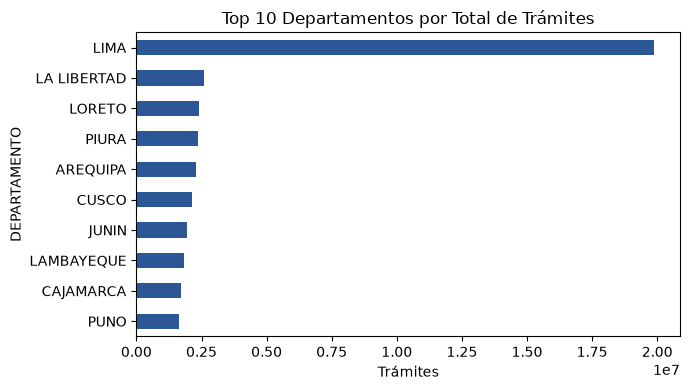

In [2]:
os.makedirs("imagenes", exist_ok=True)
top_dep = df.groupby('DEPARTAMENTO')['TRANSACCIONES'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 4))
top_dep.sort_values().plot(kind='barh', color='#2b5797')
plt.title('Top 10 Departamentos por Total de Trámites')
plt.xlabel('Trámites')
plt.tight_layout()
plt.savefig("imagenes/grafico_top_departamentos.png", dpi=150)
plt.show()

## 3. Gráfico 2: Distribución por Tipo de Trámite

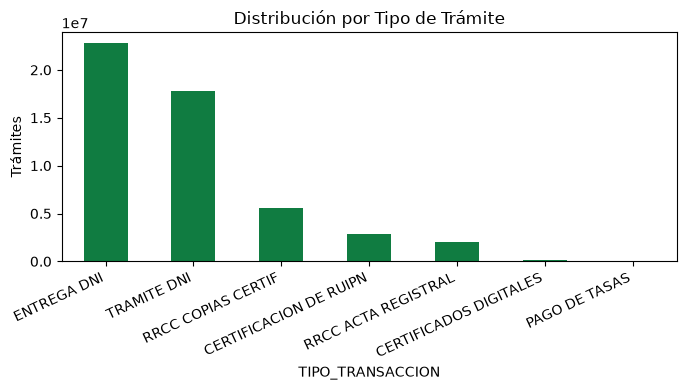

In [3]:
top_tram = df.groupby('TIPO_TRANSACCION')['TRANSACCIONES'].sum().sort_values(ascending=False)
plt.figure(figsize=(7, 4))
top_tram.plot(kind='bar', color='#107c41')
plt.title('Distribución por Tipo de Trámite')
plt.ylabel('Trámites')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig("imagenes/grafico_tipo_tramite.png", dpi=150)
plt.show()

## 4. Gráfico 3: Evolución Anual

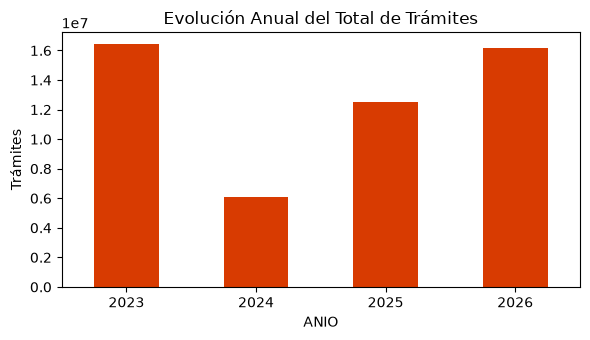

In [4]:
trend = df.groupby('ANIO')['TRANSACCIONES'].sum()
plt.figure(figsize=(6, 3.5))
trend.plot(kind='bar', color='#d83b01')
plt.title('Evolución Anual del Total de Trámites')
plt.ylabel('Trámites')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("imagenes/grafico_tendencia_anual.png", dpi=150)
plt.show()

## 5. Respuestas a preguntas analíticas
- **P1:** Lima lidera con 19.8M de trámites (38.8% del país), seguida por La Libertad (2.6M) y Loreto (2.4M).
- **P2:** Entrega de DNI (44.5%) y Trámite de DNI (34.8%) concentran el 79.3% de la demanda.
- **P3:** El flujo se mantiene estable sobre los 12.5M de trámites anuales.